# Neural Networks mode Hidden Neurons

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as f
from torch.utils.data import DataLoader,Dataset

In [2]:
# define the plotting function
def get_hist(model,data_set):
    activitions = model.activation(data_set.x)
    for i,activition in enumerate(activitions):
        plt.hist(activition.numpy(),4, density=True)
        plt.title('activition layer ' + str(i + 1))
        plt.xlabel('activition')
        plt.legend()    

In [3]:
def plotstuff(X,Y,model= None, leg=False):
    plt.plot(X[Y==0].numpy(),Y[Y==0].numpy(),'or',label='training points y=0')
    plt.plot(X[Y==1].numpy(),Y[Y==1].numpy(),'ob',label='training points y=1')
    if model != None:
        plt.plot(X.numpy(),model(X).detach().numpy(), label='neural network')

    plt.legend()

## Get Data

In [6]:
class Data(Dataset):
    def __init__(self):
        self.x = torch.linspace(-20,20,100).view(-1,1)
        self.y = torch.zeros(self.x.shape[0])
        self.y[(self.x[:,0] > -10) & (self.x[:,0] < -5)] = 1
        self.y[(self.x[:,0] > 5) & (self.x[:,0] < 10)] = 1
        self.len = self.x.shape[0]

    def __getitem__(self, index):
        return self.x[index] , self.y[index]

    def __len__(self):
        return self.len

## Define the Neural Networks , optimizer and train the model

In [7]:
# create model
class Net(nn.Module):
    def __init__(self, D_in, H, D_out):
        super(Net, self).__init__()
        self.linear1 = nn.Linear(D_in,H)
        self.linear2 = nn.Linear(H,D_out)

    def forward(self,x):
        x = torch.sigmoid(self.linear1(x))
        x = torch.sigmoid(self.linear2(x))
        return x

In [11]:
# Create function to train model
def train(data_set , model, crt, train_loader, opt, epochs=5, plot_number=10):
    cost = []
    for epoch in range(epochs):
        total=0
        for x,y in train_loader:
            opt.zero_grad()
            yhat = model(x)
            loss = crt(yhat, y.view(-1, 1).float())
            loss.backward()
            opt.step()
            total += loss.item()

        if epoch % plot_number == 0:
            plotstuff(data_set.x,data_set.y,model)

        cost.append(total)
    plt.figure()
    plt.plot(cost)
    plt.xlabel('epoch')
    plt.ylabel('cost')
    return cost

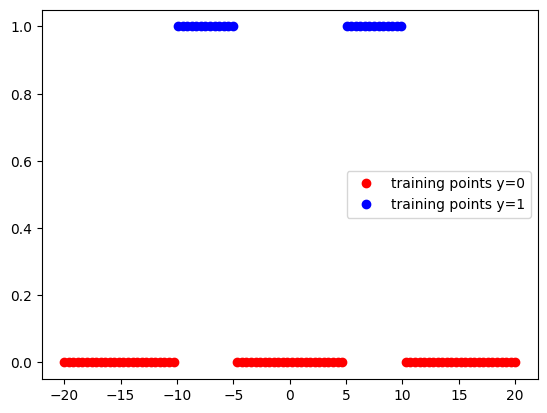

In [12]:
data_set = Data()
plotstuff(data_set.x,data_set.y,leg=False)

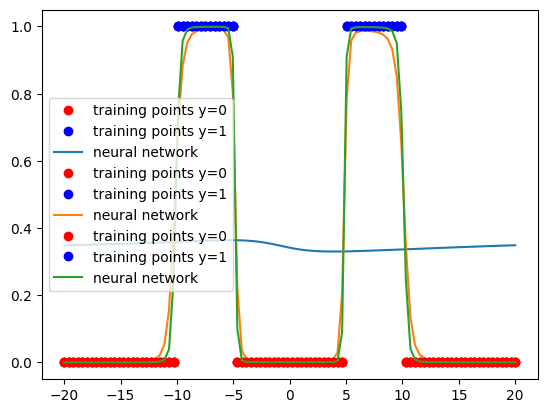

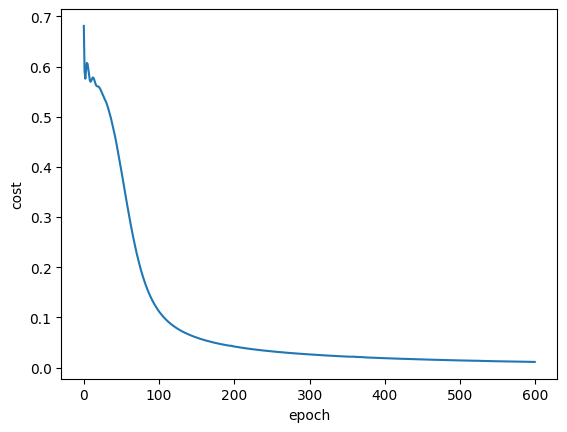

In [13]:
# create model with 9 neural in the hidden layer

torch.manual_seed(0)
model = Net(1,9,1)
lr = 0.1
crt = nn.BCELoss()
opt = torch.optim.Adam(model.parameters(),lr = lr)
train_loader = DataLoader(dataset=data_set, batch_size=100)
COST = train(data_set, model, crt, train_loader, opt, epochs=600, plot_number=200)